# ECG QRS-peak benchmark: walkthrough

This notebook walks through one record end to end, then shows the conventional baseline.
Run `python -m ecgbench.cli prepare` once before starting (see README).

**Terms.** An *ECG* records the heart's electrical activity (voltage over time). A *lead* is one
view of it; we use **Lead II**. The *QRS complex* is the sharp spike of each heartbeat. LUDB's
cardiologists marked the *peak* of each QRS complex: those marks are our **reference answers**.

In [1]:
from pathlib import Path
import os, json, numpy as np, pandas as pd
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
from IPython.display import Image, display
from ecgbench.config import load_config, PATHS
from ecgbench.data import load_lead, reference_peaks_s, annotation_span_s, case_id
from ecgbench.split import load_split
cfg = load_config()
cfg["task"]

{'lead': 'ii',
 'lead_display_name': 'Lead II',
 'qrs_peak_symbol': 'N',
 'scoring_window_s': [3.0, 7.0],
 'tolerance_s': 0.15}

## 1. The split
Records are randomly divided (seed 42) into a **development** set, used to build and debug
everything, and a **held-out test** set, which stays untouched until the protocol is frozen.

In [2]:
split = load_split()
split.groupby("partition").agg(records=("record", "size"), pilot=("pilot", "sum"))

,records,pilot
partition,,
dev,100,20
test,100,0


## 2. Load one development record
We read Lead II by name, in millivolts, and the expert annotations. Annotation positions are
sample numbers; seconds = sample / 500.

In [3]:
record = int(split.query("pilot").record.min())
sig = load_lead(cfg, record)
refs = reference_peaks_s(cfg, record)
print(f"record {record}: {len(sig.signal)} samples at {sig.fs:.0f} Hz in {sig.units}")
print("expert QRS peaks (s):", refs.round(3))
print("annotations cover %.2f-%.2f s of the 10 s recording" % annotation_span_s(cfg, record))

record 4: 5000 samples at 500 Hz in mV
expert QRS peaks (s): [1.072 2.046 3.024 4.024 5.026 6.022 6.99  7.95  8.922]
annotations cover 1.03-8.97 s of the 10 s recording


Note the last line: experts did **not** label the first ~1-2 s or the last ~1-2 s. That is why
we only score peaks inside a fixed **3.0-7.0 s window** (see `docs/protocol.md`).

## 3. What the model sees
A clean image with an opaque filename. No markers, no counts, no record number.

case id: c_5f75ddcf0f


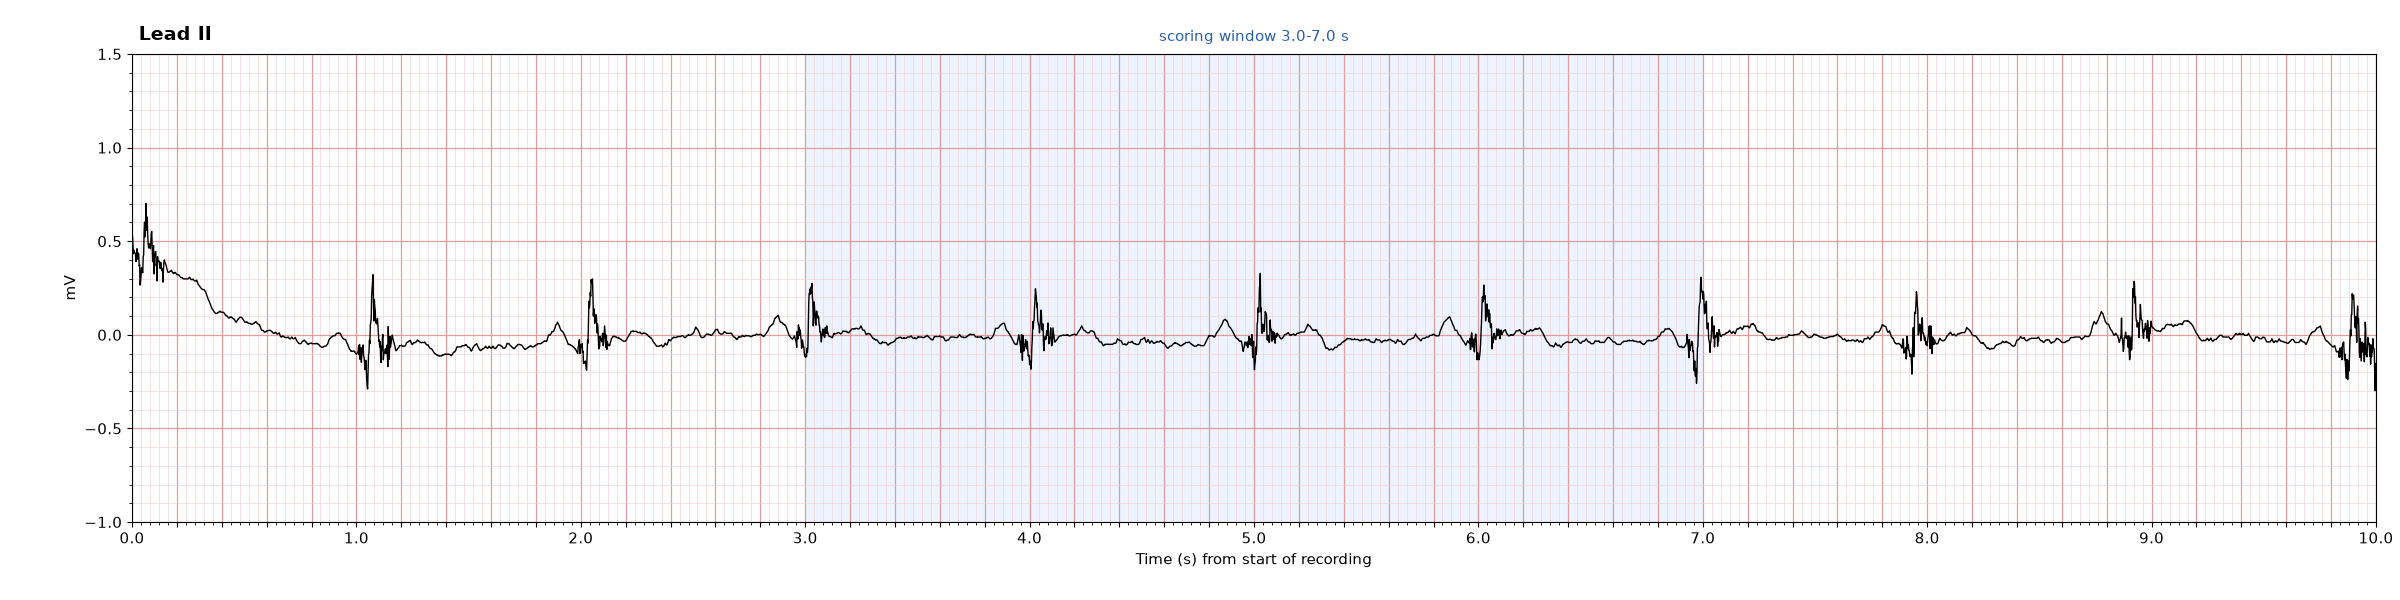

In [4]:
cid = case_id(cfg, record)
print("case id:", cid)
display(Image(filename=str(PATHS["model_inputs"] / f"{cid}.png"), width=1000))

## 4. The prompt

In [5]:
from ecgbench.models import build_prompt
system, user = build_prompt(cfg, "image_zoom")
print(system, "\n---\n", user)

You are taking part in a measurement benchmark. You will see an image of a
single-lead electrocardiogram (ECG) strip. Your job is to read waveform timing
from the image as precisely as you can. This is not a diagnostic task. 
---
 The image shows Lead II of a 10-second ECG recording. The horizontal axis
is time in seconds measured from the start of the recording (0.0 s at the left
edge, 10.0 s at the right edge). The vertical axis is voltage in millivolts (mV).
Major grid lines are every 0.2 s and 0.5 mV; minor grid lines are every 0.04 s
and 0.1 mV.

Task: list the time of the peak of every QRS complex in Lead II whose peak
falls inside the scoring window 3.0 s to 7.0 s (the
shaded region). For each QRS complex, mark the top of its upward (positive)
deflection, the R wave, even when that upward part is small compared with a
downward part. Narrow vertical pacemaker spikes are not QRS peaks.

Report times in seconds from the start of the recording (not relative to the
window), as decima

## 5. Score a prediction
Here we use a **MOCK** prediction made from the answers with noise, one deleted peak and one
added peak. It is only for testing the scorer and is **not a model result**.

In [6]:
from ecgbench.scoring import score_case
from ecgbench.responses import parse_response
mock_text = json.dumps({"qrs_peaks_s": [3.03, 3.52, 4.02, 6.02, 6.98]})
parsed = parse_response(mock_text, duration_s=10.0)
s = score_case(parsed.peaks_s, refs, (3.0, 7.0), 0.150, parsed.valid)
print(f"TP={s.tp}  FP={s.fp}  FN={s.fn}  passed={s.passed}")
print("timing errors (ms):", np.round(np.array(s.errors_s) * 1000, 1))

TP=4  FP=1  FN=1  passed=False
timing errors (ms): [  6.  -4.  -2. -10.]


**Matching rule:** each prediction can pair with at most one reference, only within 150 ms; we
pick the pairing with the most matches, then the smallest total error. `tests/test_scoring.py`
checks the tricky cases (ties, tolerance edge, duplicates, wrong units).

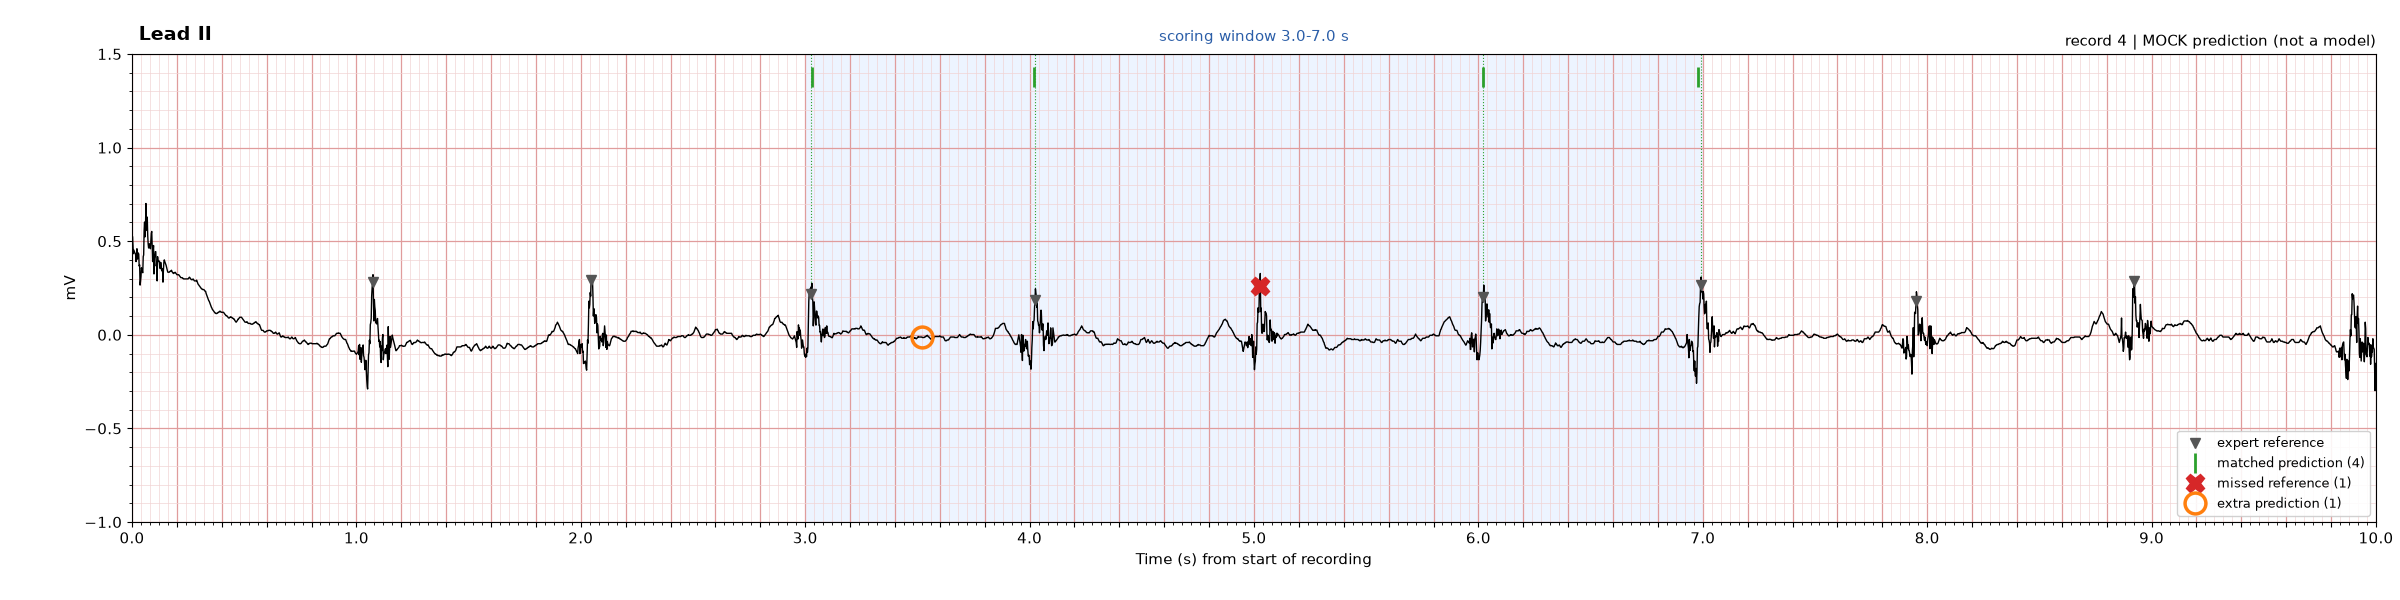

In [7]:
from ecgbench.render import render_overlay
out = PATHS["results"] / "example" / f"notebook_overlay_{cid}.png"
render_overlay(sig, s, refs, cfg, out, f"record {record} | MOCK prediction (not a model)", parsed.peaks_s)
display(Image(filename=str(out), width=1000))

## 6. Conventional baseline: XQRS
XQRS reads the **numbers** directly, not an image, so it gets different information than a
vision model. We report it separately.

In [8]:
from ecgbench.baseline import xqrs_peaks_s
xq = xqrs_peaks_s(sig, cfg)
sx = score_case(xq, refs, (3.0, 7.0), 0.150)
print(f"XQRS on record {record}: TP={sx.tp} FP={sx.fp} FN={sx.fn}")
pd.read_csv(PATHS["results"] / "dev" / "baseline" / "summary.csv").set_index("variant").T

XQRS on record 4: TP=5 FP=0 FN=0


variant,xqrs_raw,xqrs_corrected
partition,dev,dev
n_cases,100,100
tp,403,403
fp,0,0
fn,35,35
precision,1.0,1.0
recall,0.920091,0.920091
f1,0.958383,0.958383
case_pass_rate,0.9,0.9
invalid_rate,0.0,0.0


## 7. The zoom tool
In the zoom condition the model can ask for a closer view. The tool crops a high-resolution
clean render; it never looks at the answers.

Zoomed view of 3.00-4.20 s. Time labels are seconds from the start of the recording; labeled grid lines every 0.2 s, minor grid every 0.04 s.


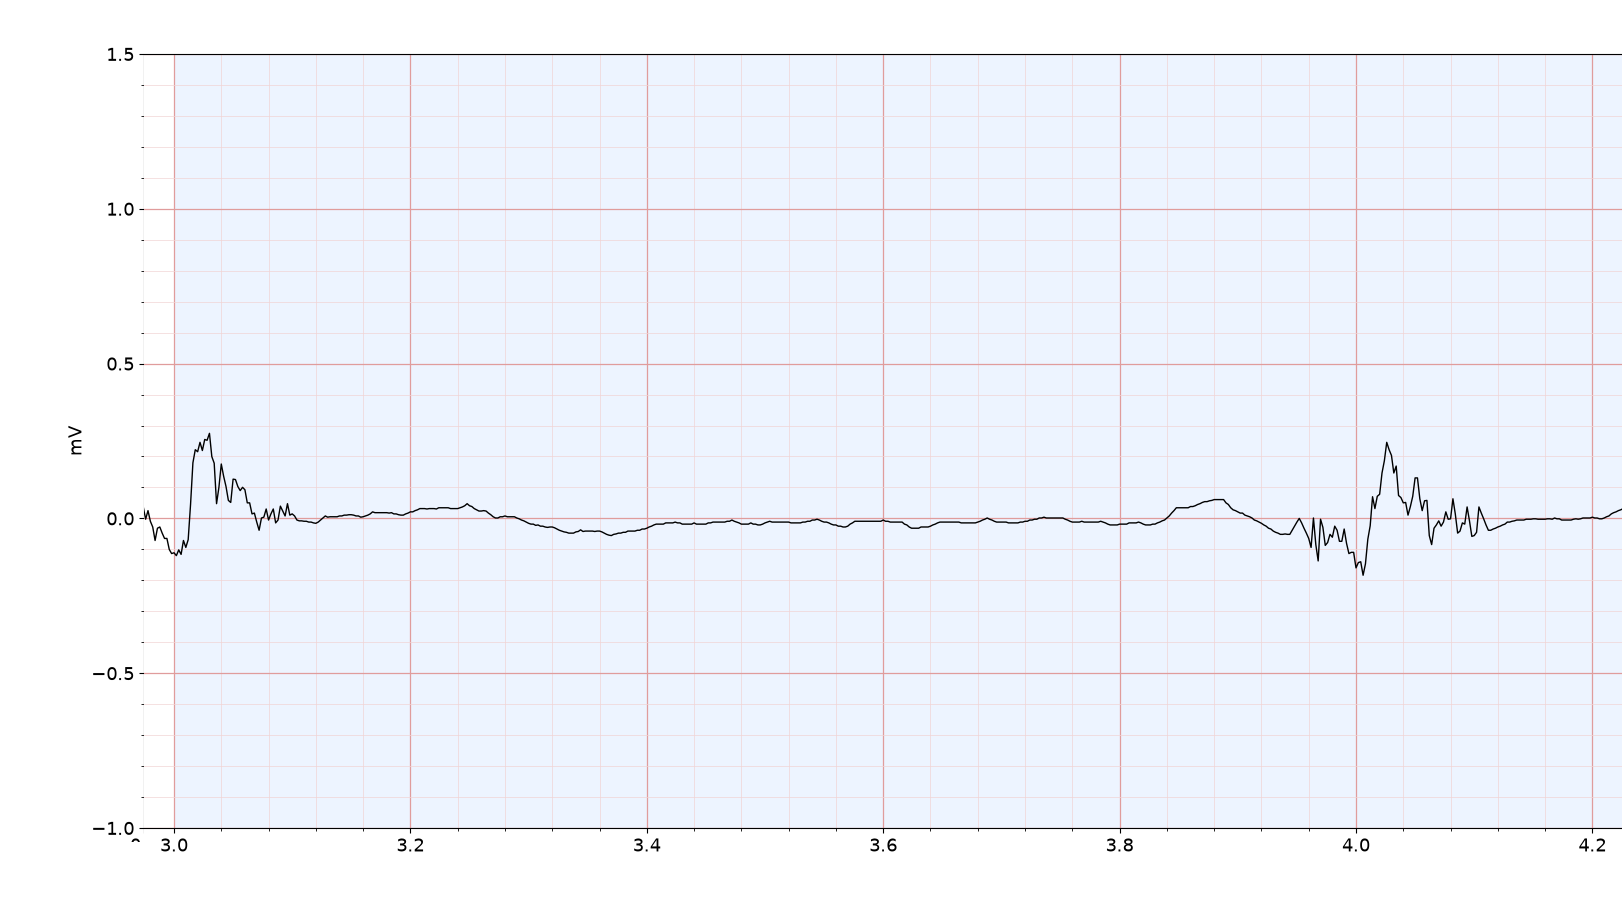

In [9]:
from ecgbench.models import ZoomTool
from ecgbench.runner import case_input
ok, msg, png = ZoomTool(case_input(cid), cfg)({"start_s": 3.0, "end_s": 4.2})
print(msg); display(Image(data=png, width=700))

## 8. Model runs
Model runs need an API key and a budget. See README ("Run") and `STATUS.md` for the current state.
Results land in `results/dev/runs/<run-name>/attempts.jsonl` and are summarized with
`python -m ecgbench.cli summarize <path>`.